Saving WhatsApp Image 2026-09-18 at 14.07.17.jpeg to WhatsApp Image 2026-09-18 at 14.07.17.jpeg
Nama file: WhatsApp Image 2026-09-18 at 14.07.17.jpeg
Ukuran gambar: (720, 1017)


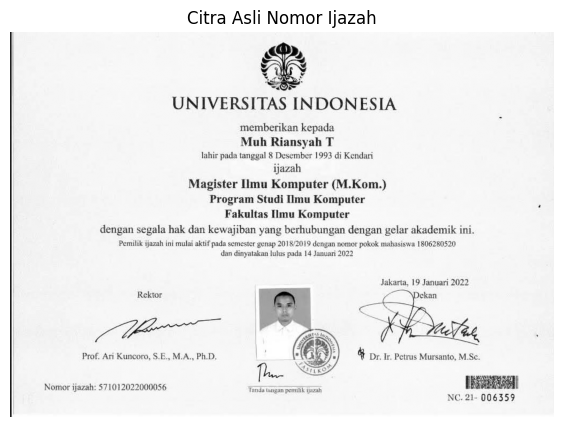

In [1]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from PIL import Image
import io

# Upload gambar nomor ijazah
uploaded = files.upload()

# Membaca gambar yang diunggah
nama_file = next(iter(uploaded))
gambar_asli = cv2.imdecode(
    np.frombuffer(uploaded[nama_file], np.uint8),
    cv2.IMREAD_GRAYSCALE
)

if gambar_asli is None:
    raise ValueError("Gambar gagal dibaca. Silakan upload gambar lain.")

print("Nama file:", nama_file)
print("Ukuran gambar:", gambar_asli.shape)

plt.figure(figsize=(10, 5))
plt.imshow(gambar_asli, cmap="gray")
plt.title("Citra Asli Nomor Ijazah")
plt.axis("off")
plt.show()


In [2]:

# METODE 1: Brightness Adjustment
# Meningkatkan kecerahan dengan menambahkan nilai piksel
brightness = cv2.convertScaleAbs(
    gambar_asli, alpha=1.0, beta=35
)

# METODE 2: Contrast Stretching
# Meregangkan rentang intensitas berdasarkan persentil
p2, p98 = np.percentile(gambar_asli, (2, 98))

if p98 > p2:
    contrast = np.clip(
        (gambar_asli.astype(np.float32) - p2)
        * 255.0 / (p98 - p2),
        0, 255
    ).astype(np.uint8)
else:
    contrast = gambar_asli.copy()

# METODE 3: Histogram Equalization
hist_equalization = cv2.equalizeHist(gambar_asli)

print("Tiga metode enhancement berhasil dilakukan.")


Tiga metode enhancement berhasil dilakukan.


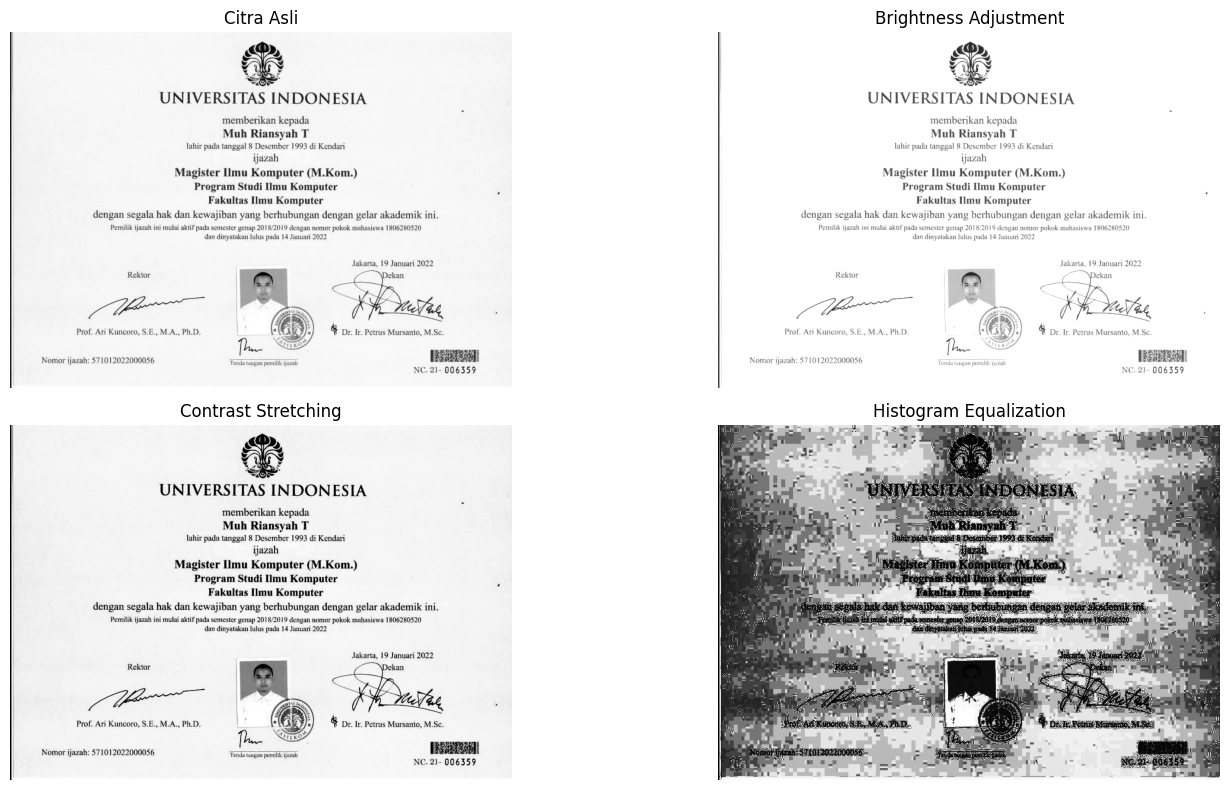

In [3]:

judul = [
    "Citra Asli",
    "Brightness Adjustment",
    "Contrast Stretching",
    "Histogram Equalization"
]

hasil = [
    gambar_asli,
    brightness,
    contrast,
    hist_equalization
]

plt.figure(figsize=(16, 8))

for i, (nama, citra) in enumerate(zip(judul, hasil)):
    plt.subplot(2, 2, i + 1)
    plt.imshow(citra, cmap="gray", vmin=0, vmax=255)
    plt.title(nama)
    plt.axis("off")

plt.tight_layout()
plt.show()


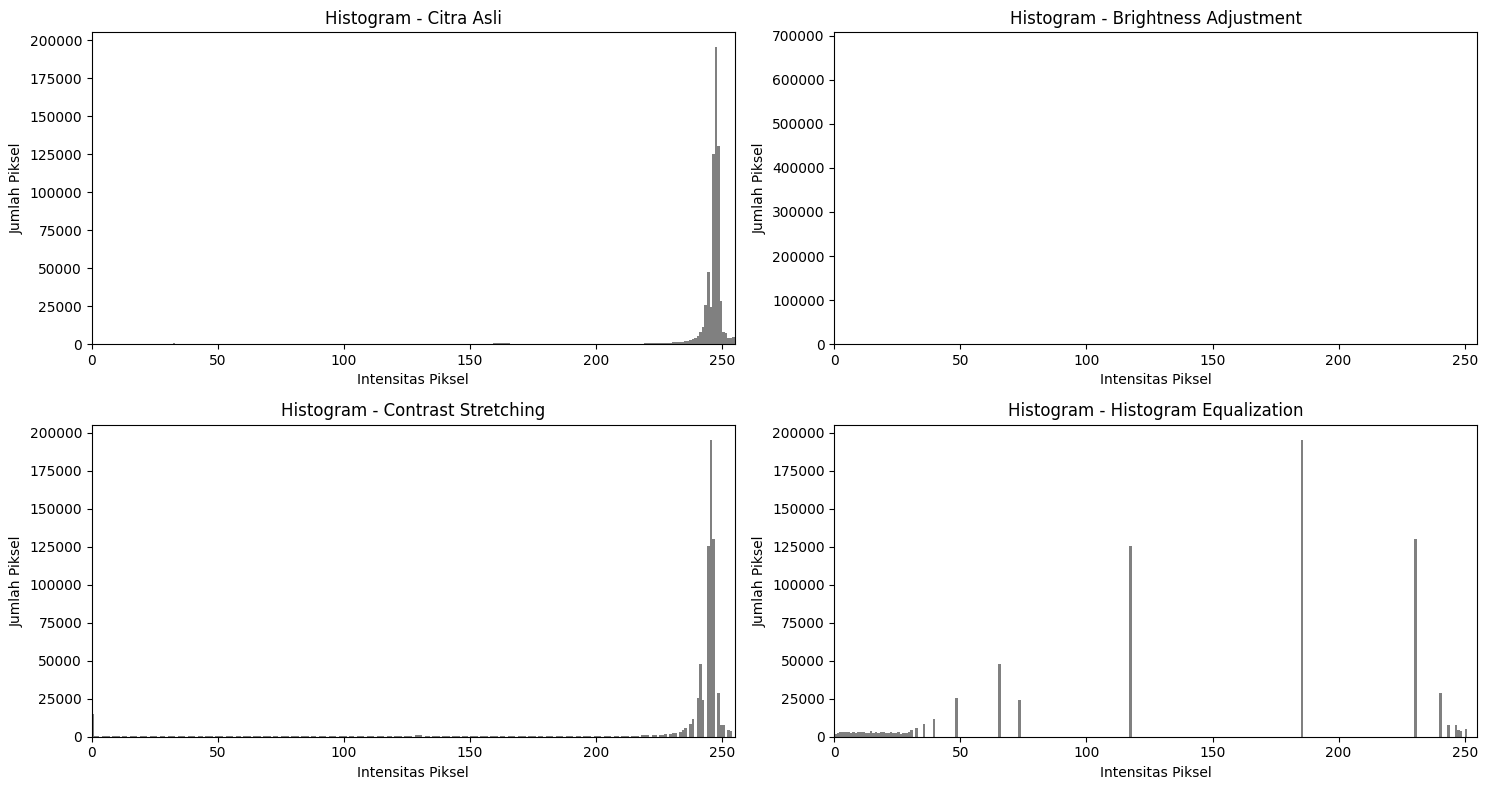

In [4]:

plt.figure(figsize=(15, 8))

for i, (nama, citra) in enumerate(zip(judul, hasil)):
    plt.subplot(2, 2, i + 1)
    plt.hist(
        citra.ravel(),
        bins=256,
        range=(0, 256),
        color="gray"
    )
    plt.title("Histogram - " + nama)
    plt.xlabel("Intensitas Piksel")
    plt.ylabel("Jumlah Piksel")
    plt.xlim(0, 255)

plt.tight_layout()
plt.show()


In [5]:

def hitung_metrik(citra):
    rata_rata = np.mean(citra)
    standar_deviasi = np.std(citra)
    kontras_rms = np.std(citra)

    return rata_rata, standar_deviasi, kontras_rms

print(f"{'Metode':<28} {'Rata-rata':>12} "
      f"{'Std Deviasi':>14} {'Kontras RMS':>14}")
print("-" * 72)

for nama, citra in zip(judul, hasil):
    mean, std, rms = hitung_metrik(citra)
    print(f"{nama:<28} {mean:>12.2f} "
          f"{std:>14.2f} {rms:>14.2f}")


Metode                          Rata-rata    Std Deviasi    Kontras RMS
------------------------------------------------------------------------
Citra Asli                         236.36          37.89          37.89
Brightness Adjustment              247.24          31.59          31.59
Contrast Stretching                231.26          47.67          47.67
Histogram Equalization             145.61          78.57          78.57


In [6]:

!apt-get -qq update
!apt-get -qq install -y tesseract-ocr
!pip -q install pytesseract

import pytesseract

print("HASIL PEMBACAAN OCR")
print("=" * 50)

for nama, citra in zip(judul, hasil):
    teks = pytesseract.image_to_string(
        citra,
        config="--psm 6"
    )

    print(f"\n{nama}:")
    print(teks.strip() if teks.strip() else
          "Tidak ada teks yang berhasil dikenali.")


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
HASIL PEMBACAAN OCR

Citra Asli:
& JJ
Le
<a
memberikan kepada
Muh Riansyah T
lahir pada tanggal 8 Desember 1993 di Kendari
ijazah
Magister IImu Komputer (M.Kom.)
Program Studi [imu Komputer "
Fakultas [Imu Komputer
dengan segala hak dan kewajiban yang berhubungan dengan gelar akademik ini.
Pemilik ijazah ini mulai aktif pada semester genap 2018/2019 dengan nomor pokok mahasiswa 1806280520
dan dinyatakan lulus pada 14 Januari 2022
Jakarta, 19 Januari 2022
| Rektor | ekan
a ay
ra, | gr ‘
Prof. Ari Kuncoro, .E., M.A., Ph.D, | "(GES);) 4 rir. Petrus Mursanto, M.Sc.
Nomor ijazah: 571012022000056 Tc el
NC. 21- 006359

Brightness Adjustment:
G re,
Ly Ti
MY

memberikan kepada

Muh Riansyah T

lahir pada tanggal 8 Desember 1993 di Kendari
ijazah
Magister Ilmu Komputer (M.Kom.)
Program Studi [imu Komputer ,
Fa